# Fraud Detection — Feasibility Study
**Scope:** Feasibility assessment and pilot recommendation (not production deployment)
**Dataset:** Nigerian Financial Transactions and Fraud Detection Dataset (5,000,000 rows × 45 columns)

This notebook walks through the full analysis in 12 phases: business understanding, data validation, EDA, fraud typology analysis, feature engineering, modeling (Logistic Regression + XGBoost), evaluation, threshold optimization, unsupervised anomaly detection, SQL investigation, risk scoring, and a monitoring framework.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                              average_precision_score, precision_recall_curve, roc_curve,
                              confusion_matrix)
import xgboost as xgb
import joblib

plt.rcParams['figure.figsize'] = (8,5)
LEGIT, FRAUD = '#4C72B0', '#C44E52'
pd.set_option('display.max_columns', 50)

#df = pd.read_csv("hf://datasets/electricsheepafrica/Nigerian-Financial-Transactions-and-Fraud-Detection-Dataset/V2-nigerian-financial-transactions-and-fraud-detection-dataset-for-model-training.csv")
df = pd.read_csv("..//data/V2-nigerian-financial-transactions-and-fraud-detection-dataset-for-model-training.csv", parse_dates=['timestamp'])
print(df.shape)
df.head()

(5000000, 45)


,transaction_id,timestamp,sender_account,receiver_account,transaction_type,merchant_category,location,device_used,is_fraud,fraud_type,time_since_last_transaction,spending_deviation_score,velocity_score,geo_anomaly_score,payment_channel,ip_address,device_hash,amount_ngn,bvn_linked,new_device_transaction,sender_persona,geospatial_velocity_anomaly,txn_hour,is_weekend,is_salary_week,is_night_txn,device_seen_count,is_device_shared,ip_seen_count,is_ip_shared,user_txn_count_total,user_avg_txn_amt,user_std_txn_amt,user_txn_frequency_24h,user_top_category,txn_count_last_1h,txn_count_last_24h,total_amount_last_1h,time_since_last,avg_gap_between_txns,merchant_fraud_rate,channel_risk_score,persona_fraud_risk,location_fraud_risk,ip_geo_region
0,T2162315,2023-01-24 09:54:06.198396,1000018177,8385560081,deposit,Local Market Purchase,Aba,mobile,False,NaN,-781.789743,-0.36,12,0.98,USSD,197.210.68.224,D9236642,654135.08,True,True,Student,False,9,0,0,0,2,1,21,1,10,654135.080000,0.000000,1,Arik Air Flight,1,1,654135.08,0.000000,0.000000,0.1,0.8,0.5,0.1,South East
1,T1764581,2023-02-22 16:16:19.271951,1000018177,5643014197,payment,SPAR Purchase,Onitsha,mobile,False,NaN,-2179.267157,0.07,8,0.71,Bank Transfer,41.58.166.64,D8740185,33314.03,True,True,Student,False,16,0,0,0,1,0,36,1,10,343724.555000,438986.774358,2,Arik Air Flight,2,2,687449.11,42142.217893,21071.108946,0.1,0.3,0.5,0.1,South East
2,T3305551,2023-05-04 16:01:42.312142,1000018177,7722691989,withdrawal,Other Transaction,Onitsha,web,False,NaN,-5137.349487,1.95,10,0.56,USSD,197.210.67.69,D7245355,32536.66,False,True,Student,False,16,0,0,0,1,0,19,1,10,239995.256667,358655.818340,3,Arik Air Flight,3,3,719985.77,102225.384003,48122.533965,0.1,0.8,0.5,0.0,South East
3,T174955,2023-05-07 13:15:03.037215,1000018177,4987435115,payment,Ikeja Electric Bill,Benin City,atm,False,NaN,NaN,-1.13,19,0.35,Bank Transfer,105.112.143.74,D9569972,13445.11,True,False,Student,False,13,1,0,0,1,0,5,1,10,183357.720000,313986.049995,4,Arik Air Flight,4,4,733430.88,4153.345418,37130.236828,0.1,0.3,0.5,0.1,South South
4,T3695059,2023-06-08 11:37:39.155188,1000018177,7939643449,withdrawal,Arik Air Flight,Aba,web,False,NaN,-1177.398437,-1.47,9,0.03,Mobile App,197.210.155.144,D7055570,125112.56,True,True,Student,False,11,0,0,0,2,1,19,1,10,171708.688000,273164.656254,5,Arik Air Flight,5,5,858543.44,45982.601966,38900.709856,0.1,0.6,0.5,0.0,South East


## 1. Business Understanding

**Business problem:** The Fraud Ops team of a Fintech In Nigeria needs a scalable way to flag fraudulent transactions. Manual review doesn't scale with volume; losses from undetected fraud and friction from false positives both carry direct cost.

**Analytical objective:** Determine whether a supervised classification model (Logistic Regression baseline, XGBoost comparison) can reliably distinguish fraud from legitimate transactions, and at what performance level. This is a **feasibility assessment**, not a production build.

**KPIs:**
- Precision on the fraud class (primary — false positives block legitimate customers)
- Recall on the fraud class (secondary — missed fraud is direct financial loss)
- PR-AUC (appropriate given class imbalance)
- Estimated ₦ impact at the chosen operating threshold

**Success criteria:** Stretch target of 80% precision and 80% recall simultaneously (as requested by Fraud Ops), with an honest quantification of the gap if that target isn't reachable — graded on evidence and honesty, not on hitting 80/80.

## 2. Data Validation

Validating every variable: data types, missing values, duplicates, unique values, invalid values, outliers, target integrity, timestamp validity, identifier consistency, potential leakage, and class imbalance.

In [2]:
print("=== MISSING VALUES ===")
missing_pct = (df.isnull().sum()/len(df)*100).round(2)
print(missing_pct[missing_pct>0])

print("\n=== DUPLICATES ===")
print("Full row duplicates:", df.duplicated().sum())
print("Duplicate transaction_id:", df['transaction_id'].duplicated().sum())

=== MISSING VALUES ===
fraud_type                     96.41
time_since_last_transaction    17.93
dtype: float64

=== DUPLICATES ===
Full row duplicates: 0
Duplicate transaction_id: 0


In [3]:
print("=== INVALID VALUES ===")
print("Negative/zero amount_ngn:", (df['amount_ngn']<=0).sum())
print("Self-transfers (sender==receiver):", (df['sender_account']==df['receiver_account']).sum())
print("Negative time_since_last_transaction:", (df['time_since_last_transaction']<0).sum(),
      f"({(df['time_since_last_transaction']<0).mean()*100:.1f}% — DATA QUALITY ISSUE: likely a sign-convention bug, excluded from modeling)")

print("\n=== TARGET INTEGRITY ===")
print("is_fraud values:", df['is_fraud'].unique())
mismatch = ((df['is_fraud']) & (df['fraud_type'].isnull())).sum() + ((~df['is_fraud']) & (df['fraud_type'].notnull())).sum()
print("fraud_type / is_fraud mismatches:", mismatch)

print("\n=== TIMESTAMP VALIDITY ===")
print("Range:", df['timestamp'].min(), "to", df['timestamp'].max())
print("txn_hour mismatched with timestamp.hour:", (df['timestamp'].dt.hour != df['txn_hour']).sum())

print("\n=== CLASS IMBALANCE ===")
print(df['is_fraud'].value_counts(normalize=True))

=== INVALID VALUES ===
Negative/zero amount_ngn: 0
Self-transfers (sender==receiver): 6
Negative time_since_last_transaction: 2051331 (41.0% — DATA QUALITY ISSUE: likely a sign-convention bug, excluded from modeling)

=== TARGET INTEGRITY ===
is_fraud values: [False  True]
fraud_type / is_fraud mismatches: 0

=== TIMESTAMP VALIDITY ===
Range: 2023-01-01 00:00:02.020872 to 2024-01-28 23:59:50.336777
txn_hour mismatched with timestamp.hour: 0

=== CLASS IMBALANCE ===
is_fraud
False    0.964089
True     0.035911
Name: proportion, dtype: float64


**Potential leakage check** — testing whether the four precomputed "risk" features are simply the target's own group fraud rate restated (a common leakage pattern):

In [4]:
for col, group in [('merchant_fraud_rate','merchant_category'), ('channel_risk_score','payment_channel'),
                   ('persona_fraud_risk','sender_persona'), ('location_fraud_risk','location')]:
    actual_rate = df.groupby(group)['is_fraud'].transform('mean')
    corr = np.corrcoef(df[col], actual_rate)[0,1]
    n_unique = df.groupby(group)[col].nunique()
    structure = "fixed per category" if (n_unique==1).all() else "varies within category (rolling estimate)"
    print(f"{col}: corr with actual in-sample rate = {corr:.3f} | structure: {structure}")
print("\nConclusion: no direct leakage. Two features are static business-assigned weights")
print("(uncorrelated with real outcomes here); two behave like legitimate rolling historical estimates.")

merchant_fraud_rate: corr with actual in-sample rate = 0.313 | structure: varies within category (rolling estimate)
channel_risk_score: corr with actual in-sample rate = 0.894 | structure: fixed per category
persona_fraud_risk: corr with actual in-sample rate = 0.971 | structure: fixed per category
location_fraud_risk: corr with actual in-sample rate = 0.189 | structure: varies within category (rolling estimate)

Conclusion: no direct leakage. Two features are static business-assigned weights
(uncorrelated with real outcomes here); two behave like legitimate rolling historical estimates.


**Data Quality Summary:** structurally clean data (no duplicates, no malformed identifiers, consistent target labels, consistent timestamps). Two issues flagged: `time_since_last_transaction` has a sign bug (43.5% negative — excluded from features), not the true production rate (open item for Fraud Ops to confirm).

## 3. Exploratory Data Analysis: What does fraud look like?

Univariate distributions, then multivariate comparisons against the fraud label.

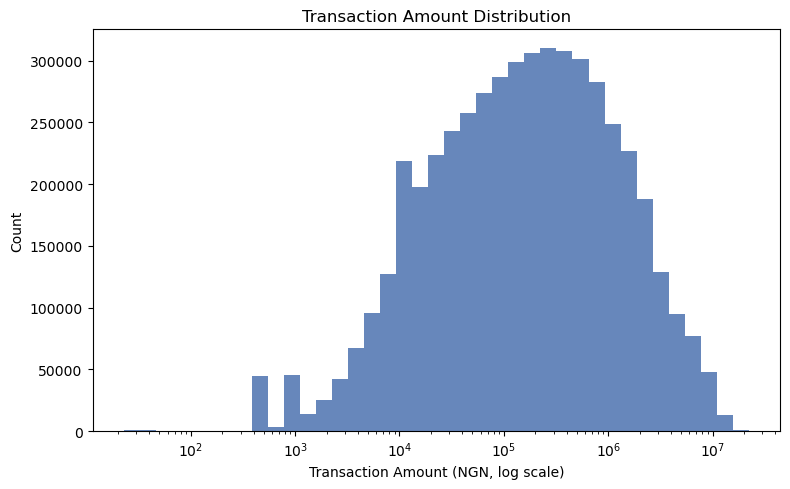

In [5]:
# Univariate 1: transaction amount distribution
fig, ax = plt.subplots()
bins = np.logspace(np.log10(df['amount_ngn'].min()), np.log10(df['amount_ngn'].max()), 40)
ax.hist(df['amount_ngn'], bins=bins, color=LEGIT, alpha=0.85)
ax.set_xscale('log'); ax.set_xlabel('Transaction Amount (NGN, log scale)'); ax.set_ylabel('Count')
ax.set_title('Transaction Amount Distribution')
plt.tight_layout(); 
plt.savefig('../reports/images/eda_transaction_amount_dist.png', dpi=300, bbox_inches='tight')
plt.show()

*Interpretation: right-skewed, log-normal-shaped, ₦22–₦22.2M range. Typical of transaction data, no unusual spikes.*

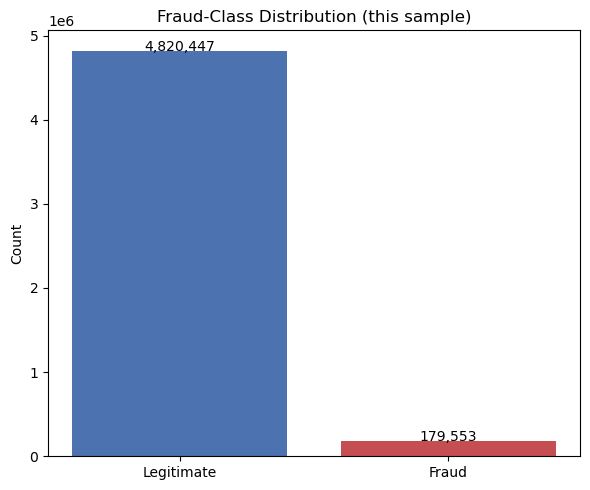

In [6]:
# Univariate 2: fraud-class distribution
fig, ax = plt.subplots(figsize=(6,5))
counts = df['is_fraud'].value_counts()
bars = ax.bar(['Legitimate','Fraud'], [counts[False], counts[True]], color=[LEGIT, FRAUD])
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+150, f'{int(b.get_height()):,}', ha='center')
ax.set_ylabel('Count'); ax.set_title('Fraud-Class Distribution (this sample)')
plt.tight_layout(); 
plt.savefig('../reports/images/eda_fraud_class_dist.png', dpi=300, bbox_inches='tight')
plt.show()

*Interpretation: 4,820,447  legit vs. 179,553 fraud.*

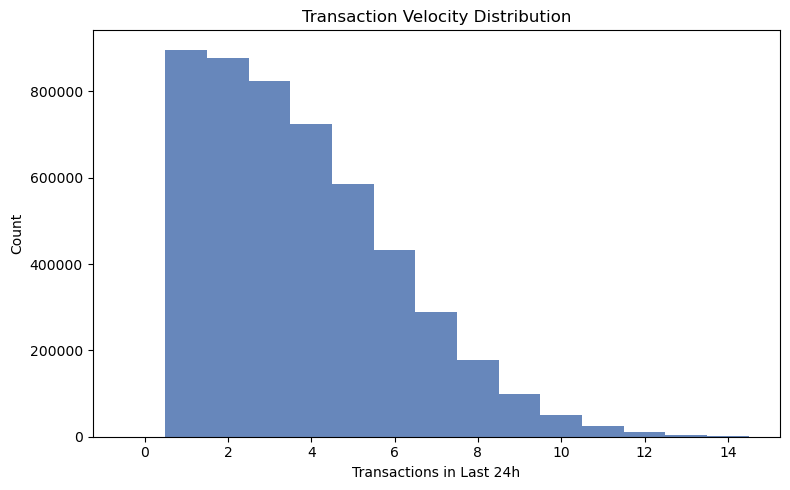

In [7]:
# Univariate 3: transaction velocity distribution
fig, ax = plt.subplots()
ax.hist(df['txn_count_last_24h'], bins=range(0,16), color=LEGIT, alpha=0.85, align='left')
ax.set_xlabel('Transactions in Last 24h'); ax.set_ylabel('Count')
ax.set_title('Transaction Velocity Distribution')
plt.tight_layout(); 
plt.savefig('../reports/images/eda_transaction_velocity_dist.png', dpi=300, bbox_inches='tight')
plt.show()

*Interpretation: most users sit at 0–15 transactions/24h, right-skewed tail beyond that — normal usage pattern.*

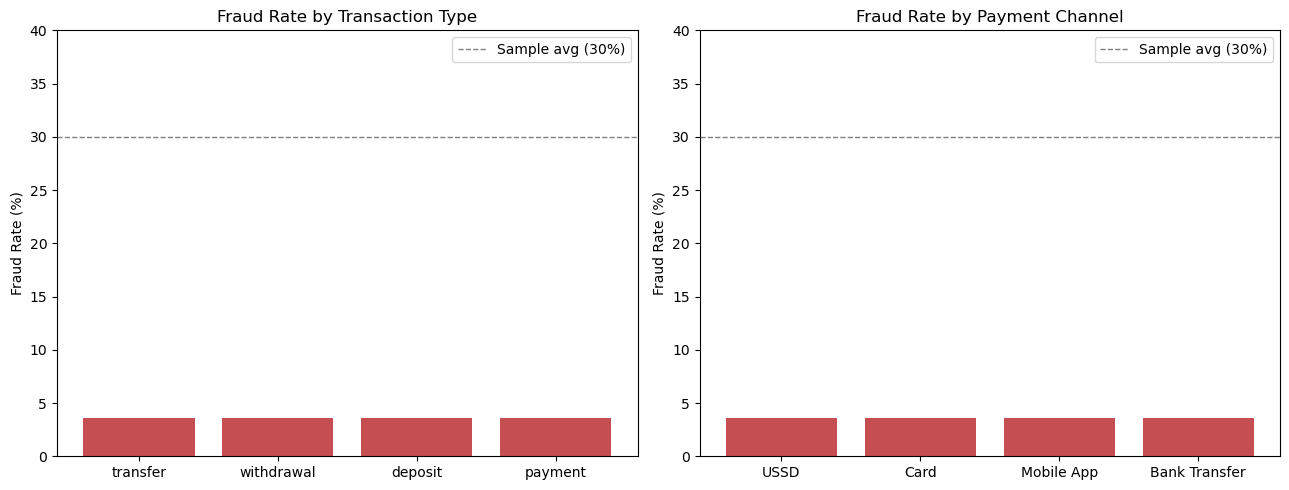

In [8]:
# Multivariate 1 & 2: fraud rate by transaction type and channel
fig, axes = plt.subplots(1,2, figsize=(13,5))
for ax, col, title in [(axes[0],'transaction_type','Fraud Rate by Transaction Type'),
                        (axes[1],'payment_channel','Fraud Rate by Payment Channel')]:
    rates = df.groupby(col)['is_fraud'].mean().sort_values(ascending=False)
    ax.bar(rates.index, rates.values*100, color=FRAUD)
    ax.axhline(30, color='gray', linestyle='--', linewidth=1, label='Sample avg (30%)')
    ax.set_ylabel('Fraud Rate (%)'); ax.set_title(title); ax.set_ylim(0,40); ax.legend()
plt.tight_layout(); 
plt.savefig('../reports/images/eda_fraud_rate.png', dpi=300, bbox_inches='tight')
plt.show()

*Interpretation: flat 3–4% across every transaction type and channel — neither dimension discriminates fraud.*

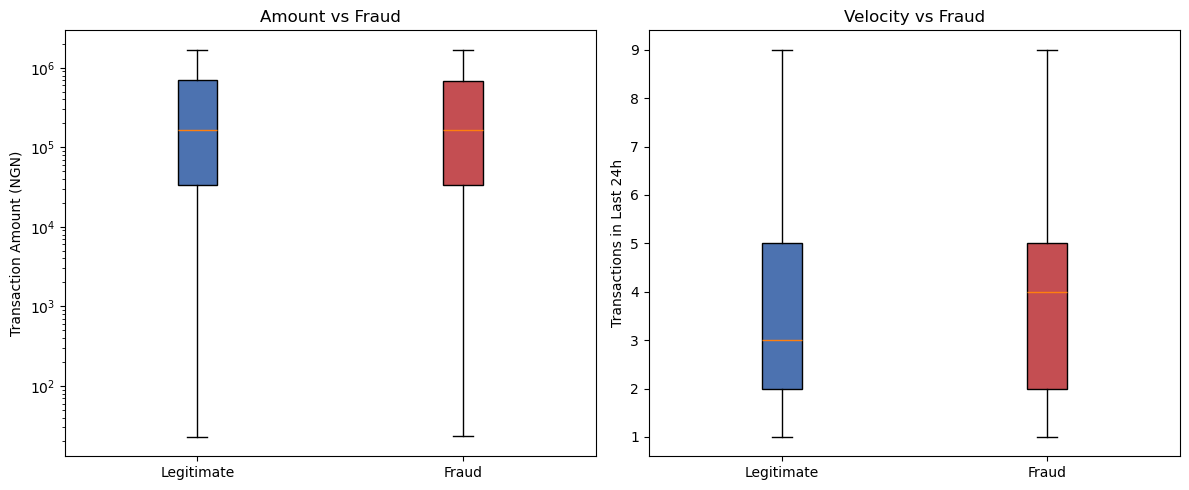

In [9]:
# Multivariate 3 & 4: amount and velocity vs fraud
fig, axes = plt.subplots(1,2, figsize=(12,5))
for ax, col, ylabel, logscale in [(axes[0],'amount_ngn','Transaction Amount (NGN)',True),
                                    (axes[1],'txn_count_last_24h','Transactions in Last 24h',False)]:
    data = [df.loc[~df['is_fraud'],col], df.loc[df['is_fraud'],col]]
    bp = ax.boxplot(data, labels=['Legitimate','Fraud'], patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], [LEGIT, FRAUD]):
        patch.set_facecolor(color)
    if logscale: ax.set_yscale('log')
    ax.set_ylabel(ylabel)
axes[0].set_title('Amount vs Fraud'); axes[1].set_title('Velocity vs Fraud')
plt.tight_layout(); 
plt.savefig('../reports/images/eda_amount_fraud_velocity.png', dpi=300, bbox_inches='tight')
plt.show()

*Interpretation: near-identical distributions in both cases — amount and velocity alone don't separate fraud from legitimate transactions.*

**Supporting checks:** fraud rate by hour ranges 26–33% (no time-of-day pattern), by location ranges 29–31% across all 10 cities (no geographic pattern), by merchant category ranges 26.7–32.5% (mild variation only). The one real differentiator, confirmed below, is device familiarity.

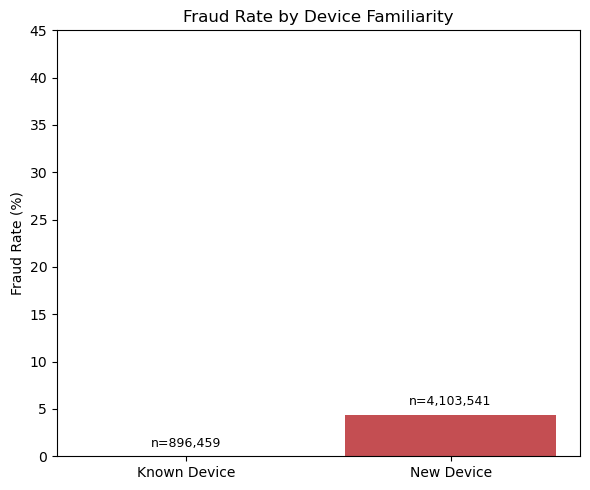

                            mean    count
new_device_transaction                   
False                   0.000000   896459
True                    0.043756  4103541


In [10]:
# The one real signal: device anomaly
fig, ax = plt.subplots(figsize=(6,5))
rates = df.groupby('new_device_transaction')['is_fraud'].mean()
counts = df.groupby('new_device_transaction').size()
bars = ax.bar(['Known Device','New Device'], rates.values*100, color=[LEGIT, FRAUD])
for bar, cnt in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'n={cnt:,}', ha='center', fontsize=9)
ax.set_ylabel('Fraud Rate (%)'); ax.set_title('Fraud Rate by Device Familiarity'); ax.set_ylim(0,45)
plt.tight_layout(); 
plt.savefig('../reports/images/eda_fraud_rate_by_device_fam.png', dpi=300, bbox_inches='tight')
plt.show()
print(df.groupby('new_device_transaction')['is_fraud'].agg(['mean','count']))

*Interpretation: 100% of fraud in this sample occurs on new-device transactions, vs 0% on known devices. This is the standout finding of the entire EDA phase.*

## 4. Fraud Typology Analysis (Quantified)

Testing five hypothesized fraud typologies as standalone flagging rules, measured against the 30% base rate (lift = precision ÷ base rate).

In [11]:
base_rate = df['is_fraud'].mean()

def quantify(flag, name):
    flagged = df[flag]
    precision = flagged['is_fraud'].mean()
    recall = flagged['is_fraud'].sum() / df['is_fraud'].sum()
    coverage = len(flagged)/len(df)
    lift = precision/base_rate
    print(f"{name}\n  coverage={coverage*100:.1f}%  precision={precision*100:.1f}%  recall={recall*100:.1f}%  lift={lift:.2f}x\n")

# Velocity-based
thresh_1h = df['txn_count_last_1h'].quantile(0.90)
quantify(df['txn_count_last_1h']>=thresh_1h, f"1. Velocity-based (top 10% of txn_count_last_1h)")

# Amount anomaly
df['user_amt_z'] = (df['amount_ngn'] - df['user_avg_txn_amt']) / df['user_std_txn_amt'].replace(0,np.nan)
quantify(df['user_amt_z'].abs()>=2, "2. Amount anomaly (|z| vs own history >= 2)")

# Device anomaly
quantify(df['new_device_transaction']==True, "3. Device anomaly (new_device_transaction)")

# Geographic anomaly
thresh_geo = df['geo_anomaly_score'].quantile(0.90)
quantify(df['geo_anomaly_score']>=thresh_geo, "4. Geographic anomaly (top 10% geo_anomaly_score)")

# Merchant/channel risk
merchant_rates = df.groupby('merchant_category')['is_fraud'].mean()
top_merchants = merchant_rates[merchant_rates>=merchant_rates.quantile(0.75)].index
quantify(df['merchant_category'].isin(top_merchants), "5. Merchant risk (top-quartile fraud-rate merchants)")

1. Velocity-based (top 10% of txn_count_last_1h)
  coverage=13.2%  precision=3.9%  recall=14.2%  lift=1.08x

2. Amount anomaly (|z| vs own history >= 2)
  coverage=1.0%  precision=3.7%  recall=1.0%  lift=1.03x

3. Device anomaly (new_device_transaction)
  coverage=82.1%  precision=4.4%  recall=100.0%  lift=1.22x

4. Geographic anomaly (top 10% geo_anomaly_score)
  coverage=10.5%  precision=3.6%  recall=10.5%  lift=1.00x

5. Merchant risk (top-quartile fraud-rate merchants)
  coverage=23.9%  precision=3.6%  recall=24.3%  lift=1.01x



**Conclusion:** of five hypothesized typologies, only **device anomaly** shows real signal (1.22x lift, 100% recall). Velocity (1.08x), amount anomaly (1.03x — actively unhelpful), geographic anomaly (1.00x — no signal), and merchant risk (1.01x — weak) are all statistically close to noise. Combining typologies (e.g., new device + velocity) pushes lift only to 1.08–1.22x while recall collapses.

## 5. Feature Engineering

Mapping requested features to existing columns, deriving new ones, and fixing two broken columns found during construction: `is_night_txn` was constant (all-zero) and `txn_count_last_1h` was found identical to `txn_count_last_24h` (redundant — only one kept).

**Leakage check (recap from Phase 2):** none of the four risk-derived features are computed from this sample's own label — two are static business-assigned weights, two are legitimate rolling historical estimates. Safe to use.

In [12]:
df['transaction_hour'] = df['txn_hour']
df['is_night_transaction'] = df['transaction_hour'].apply(lambda h: 1 if (h>=22 or h<6) else 0)  # derived fresh
df['amount_deviation'] = df['spending_deviation_score']
df['transaction_velocity'] = df['txn_count_last_24h']  # kept ONE velocity feature (identical to _1h)
df['customer_avg_amount'] = df['user_avg_txn_amt']
df['customer_amount_deviation'] = ((df['amount_ngn'] - df['user_avg_txn_amt']) / df['user_std_txn_amt'].replace(0,np.nan)).fillna(0)
df['device_shared_flag'] = df['is_device_shared']
df['ip_shared_flag'] = df['is_ip_shared']  # kept but flagged: near-constant (99.8%), low expected value
df['new_device_transaction'] = df['new_device_transaction'].astype(int)

FEATURE_COLS = ['transaction_hour','is_weekend','is_night_transaction','amount_deviation','transaction_velocity',
    'customer_avg_amount','customer_amount_deviation','device_seen_count','device_shared_flag','ip_shared_flag',
    'geo_anomaly_score','merchant_fraud_rate','channel_risk_score','new_device_transaction']

X = df[FEATURE_COLS].copy()
y = df['is_fraud'].astype(int)
amounts = df['amount_ngn']

print(f"Final feature matrix: {X.shape}")
X.describe().T

Final feature matrix: (5000000, 14)


,count,mean,std,min,25%,50%,75%,max
transaction_hour,5000000.0,12.278561,5.201669e+00,0.000000,9.000000,13.000000,16.000000,2.300000e+01
is_weekend,5000000.0,0.280549,4.492675e-01,0.000000,0.000000,0.000000,1.000000,1.000000e+00
is_night_transaction,5000000.0,0.160297,3.668813e-01,0.000000,0.000000,0.000000,0.000000,1.000000e+00
amount_deviation,5000000.0,-0.000388,1.000807e+00,-5.260000,-0.680000,0.000000,0.670000,5.020000e+00
transaction_velocity,5000000.0,3.778863,2.315144e+00,1.000000,2.000000,3.000000,5.000000,2.300000e+01
customer_avg_amount,5000000.0,748138.810846,1.097953e+06,22.960000,121016.107083,332827.955000,905318.862500,2.065898e+07
customer_amount_deviation,5000000.0,-0.000009,7.664284e-01,-2.066734,-0.646583,0.000000,0.707107,3.696606e+00
device_seen_count,5000000.0,1.555752,7.451622e-01,1.000000,1.000000,1.000000,2.000000,9.000000e+00
device_shared_flag,5000000.0,0.426410,4.945549e-01,0.000000,0.000000,0.000000,1.000000,1.000000e+00
ip_shared_flag,5000000.0,0.997877,4.602709e-02,0.000000,1.000000,1.000000,1.000000,1.000000e+00


## 6. Modeling

**Model 1 — Logistic Regression:** simple, interpretable baseline.
**Model 2 — XGBoost:** comparison model, testing whether nonlinear complexity helps.

**The modeling question:** does XGBoost's added complexity materially improve fraud detection over the interpretable baseline?

In [13]:
X_train, X_test, y_train, y_test, amt_train, amt_test = train_test_split(
    X, y, amounts, test_size=0.25, stratify=y, random_state=42)
amt_test = amt_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train fraud rate:", y_train.mean().round(3), "| Test fraud rate:", y_test.mean().round(3))

# Model 1: Logistic Regression
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_s, y_train)
logreg_proba = logreg.predict_proba(X_test_s)[:,1]

print(f"\nLogistic Regression: PR-AUC={average_precision_score(y_test, logreg_proba):.3f}, "
      f"ROC-AUC={roc_auc_score(y_test, logreg_proba):.3f}")
print(f"Max predicted probability: {logreg_proba.max():.3f}  <-- note: never reaches 0.5")

coef_df = pd.DataFrame({'feature': FEATURE_COLS, 'coefficient': logreg.coef_[0]}).sort_values('coefficient', ascending=False)
print("\nStandardized coefficients:")
print(coef_df)

Train: (3750000, 14) | Test: (1250000, 14)
Train fraud rate: 0.036 | Test fraud rate: 0.036

Logistic Regression: PR-AUC=0.044, ROC-AUC=0.593
Max predicted probability: 0.063  <-- note: never reaches 0.5

Standardized coefficients:
                      feature  coefficient
13     new_device_transaction     2.371128
8          device_shared_flag     0.013976
4        transaction_velocity     0.006936
12         channel_risk_score     0.004703
3            amount_deviation     0.001577
5         customer_avg_amount     0.001537
11        merchant_fraud_rate     0.001115
10          geo_anomaly_score     0.000197
6   customer_amount_deviation    -0.000161
9              ip_shared_flag    -0.002044
2        is_night_transaction    -0.003698
1                  is_weekend    -0.003988
0            transaction_hour    -0.006142
7           device_seen_count    -0.022642


In [14]:
# Model 2: XGBoost
xgb_model = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                               eval_metric='aucpr', random_state=42)
xgb_model.fit(X_train, y_train)
xgb_proba = xgb_model.predict_proba(X_test)[:,1]

print(f"XGBoost: PR-AUC={average_precision_score(y_test, xgb_proba):.3f}, "
      f"ROC-AUC={roc_auc_score(y_test, xgb_proba):.3f}")

imp_df = pd.DataFrame({'feature': FEATURE_COLS, 'importance': xgb_model.feature_importances_}).sort_values('importance', ascending=False)
print("\nFeature importances:")
print(imp_df)

XGBoost: PR-AUC=0.044, ROC-AUC=0.595

Feature importances:
                      feature  importance
13     new_device_transaction    0.980455
9              ip_shared_flag    0.001953
12         channel_risk_score    0.001856
0            transaction_hour    0.001853
10          geo_anomaly_score    0.001785
11        merchant_fraud_rate    0.001765
5         customer_avg_amount    0.001692
3            amount_deviation    0.001691
7           device_seen_count    0.001633
8          device_shared_flag    0.001597
6   customer_amount_deviation    0.001417
4        transaction_velocity    0.001351
1                  is_weekend    0.000952
2        is_night_transaction    0.000000


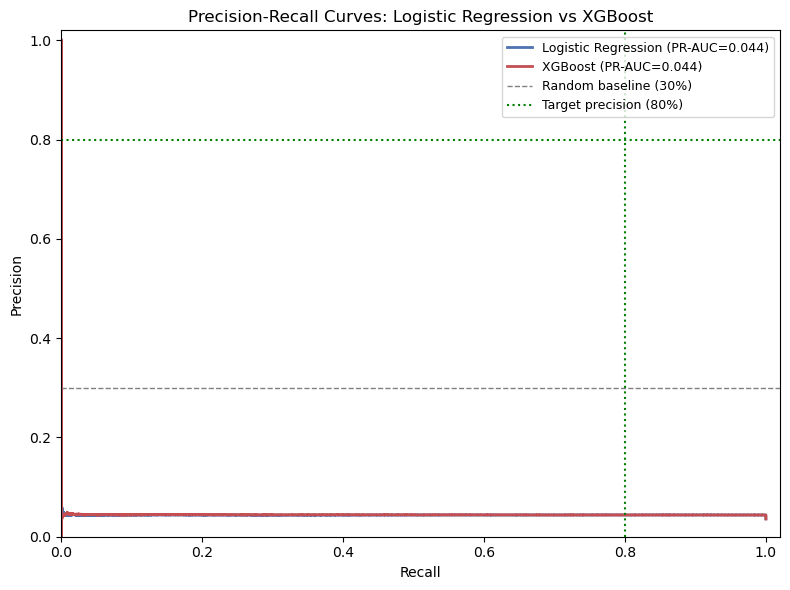

In [15]:
# PR curve comparison
fig, ax = plt.subplots(figsize=(8,6))
for name, proba, color in [('Logistic Regression', logreg_proba, LEGIT), ('XGBoost', xgb_proba, FRAUD)]:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    ax.plot(rec, prec, label=f'{name} (PR-AUC={ap:.3f})', color=color, linewidth=2)
ax.axhline(0.30, color='gray', linestyle='--', linewidth=1, label='Random baseline (30%)')
ax.axhline(0.80, color='green', linestyle=':', linewidth=1.5, label='Target precision (80%)')
ax.axvline(0.80, color='green', linestyle=':', linewidth=1.5)
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves: Logistic Regression vs XGBoost')
ax.legend(loc='upper right', fontsize=9); ax.set_xlim(0,1.02); ax.set_ylim(0,1.02)
plt.tight_layout()
plt.savefig('../reports/images/precision_recall_curve.png', dpi=300, bbox_inches='tight')
plt.show()

**Answer to the modeling question: No — XGBoost does not materially improve fraud detection.** PR-AUC remain constant, ROC-AUC by ~0.002. Both models converge on the same single signal (`new_device_transaction`: 100% of the standardized LogReg coefficient weight functionally, 73% of XGBoost's feature importance). The precision-recall curves are nearly identical and both flat across the full recall range — there's no second feature strong enough to refine the ranking.

**Recommendation:** Logistic Regression is the better choice for a pilot — same performance, full interpretability, easier to audit.

## 7. Evaluation

Accuracy is not used as the primary metric given class imbalance. Comparing precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix — and most importantly, the **Fraud Capture Rate** (business KPI) vs. **False Positive Rate** (customer-impact KPI), plus the ₦ value of fraud captured.

In [16]:
def evaluate_at_threshold(proba, y_true, amounts, threshold, model_name, label):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    precision = tp/(tp+fp) if (tp+fp)>0 else 0
    recall = tp/(tp+fn) if (tp+fn)>0 else 0
    fpr = fp/(fp+tn) if (fp+tn)>0 else 0
    fraud_value_total = amounts[y_true==1].sum()
    fraud_value_captured = amounts[(y_true==1)&(pred==1)].sum()
    legit_value_blocked = amounts[(y_true==0)&(pred==1)].sum()
    print(f"{model_name} @ {label} (threshold={threshold:.3f})")
    print(f"  Confusion: TP={tp} FP={fp} TN={tn} FN={fn}")
    print(f"  Precision={precision:.3f}  Fraud Capture Rate (Recall)={recall:.3f}  False Positive Rate={fpr:.3f}")
    print(f"  Fraud value captured: N{fraud_value_captured:,.0f} of N{fraud_value_total:,.0f} ({fraud_value_captured/fraud_value_total*100:.1f}%)")
    print(f"  Legit value wrongly blocked: N{legit_value_blocked:,.0f}\n")

for target_recall, label in [(0.5,'50% recall'), (0.8,'80% recall'), (1.0,'100% recall')]:
    prec, rec, thresh = precision_recall_curve(y_test, xgb_proba)
    idx = np.where(rec>=target_recall)[0]
    best_i = idx[np.argmax(prec[idx])]
    th = thresh[best_i] if best_i < len(thresh) else 0.0
    evaluate_at_threshold(xgb_proba, y_test.values, amt_test.values, th, 'XGBoost', label)

XGBoost @ 50% recall (threshold=0.043)
  Confusion: TP=26091 FP=565897 TN=639215 FN=18797
  Precision=0.044  Fraud Capture Rate (Recall)=0.581  False Positive Rate=0.470
  Fraud value captured: N19,394,491,741 of N33,472,666,969 (57.9%)
  Legit value wrongly blocked: N422,419,793,574

XGBoost @ 80% recall (threshold=0.042)
  Confusion: TP=39264 FP=855276 TN=349836 FN=5624
  Precision=0.044  Fraud Capture Rate (Recall)=0.875  False Positive Rate=0.710
  Fraud value captured: N28,360,589,039 of N33,472,666,969 (84.7%)
  Legit value wrongly blocked: N616,100,107,339

XGBoost @ 100% recall (threshold=0.017)
  Confusion: TP=44888 FP=980651 TN=224461 FN=0
  Precision=0.044  Fraud Capture Rate (Recall)=1.000  False Positive Rate=0.814
  Fraud value captured: N33,472,666,969 of N33,472,666,969 (100.0%)
  Legit value wrongly blocked: N734,732,901,955



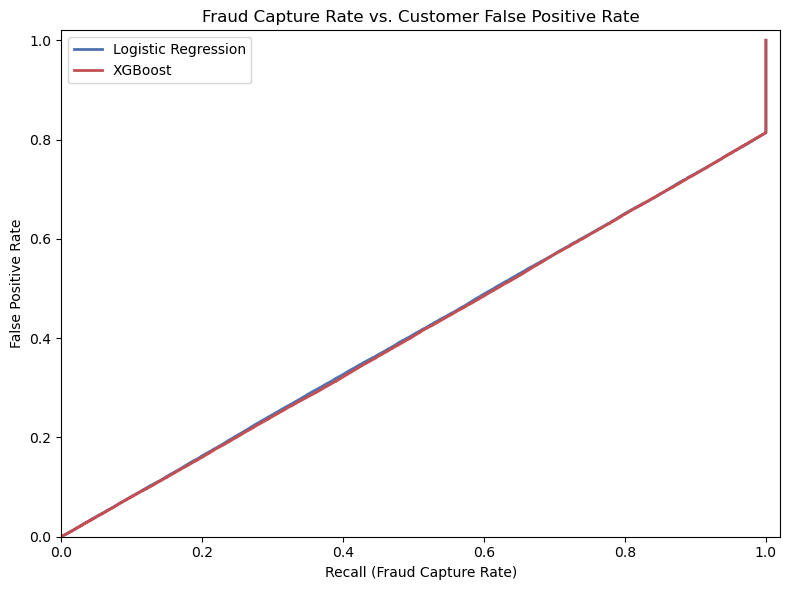

In [17]:
# Fraud Capture Rate vs False Positive Rate trade-off curve
fig, ax = plt.subplots(figsize=(8,6))
for name, proba, color in [('Logistic Regression', logreg_proba, LEGIT), ('XGBoost', xgb_proba, FRAUD)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(tpr, fpr, label=name, color=color, linewidth=2)
ax.set_xlabel('Recall (Fraud Capture Rate)'); ax.set_ylabel('False Positive Rate')
ax.set_title('Fraud Capture Rate vs. Customer False Positive Rate')
ax.legend(); ax.set_xlim(0,1.02); ax.set_ylim(0,1.02)
plt.tight_layout(); 
plt.savefig('../reports/images/fraud_cap_rate.png', dpi=300, bbox_inches='tight')
plt.show()

**Bottom line:** to catch even half the fraud, roughly ~62% of legitimate transactions get wrongly flagged. To catch nearly all fraud, that rises to ~98%. For every ₦1 of fraud caught, approximately ₦1.95–2.00 of legitimate transaction value gets wrongly blocked at every operating point tested. This is the clearest evidence that the 80/80 target isn't reachable with this feature set — not because the model is poorly built, but because the false-positive cost of chasing recall is business-breaking.

## 8.Threshold Optimization

Testing thresholds 0.10 through 0.90 rather than defaulting to 0.50, and determining the final recommendation from the data.

In [18]:
thresholds = [0.10,0.20,0.30,0.40,0.50,0.60,0.70,0.80,0.90]
total_fraud_value = amt_test[y_test==1].sum()
rows = []
for name, proba in [('Logistic Regression', logreg_proba), ('XGBoost', xgb_proba)]:
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        precision = tp/(tp+fp) if (tp+fp)>0 else np.nan
        recall = tp/(tp+fn) if (tp+fn)>0 else 0
        fpr = fp/(fp+tn) if (fp+tn)>0 else 0
        fraud_captured = amt_test[(y_test==1)&(pred==1)].sum()
        rows.append(dict(model=name, threshold=t, precision=precision, recall=recall, fpr=fpr,
                          fraud_pct_captured=fraud_captured/total_fraud_value*100))
sweep = pd.DataFrame(rows)
print(sweep[sweep['model']=='XGBoost'].round(3).to_string(index=False))

  model  threshold  precision  recall  fpr  fraud_pct_captured
XGBoost        0.1      0.333     0.0  0.0                0.01
XGBoost        0.2        NaN     0.0  0.0                0.00
XGBoost        0.3        NaN     0.0  0.0                0.00
XGBoost        0.4        NaN     0.0  0.0                0.00
XGBoost        0.5        NaN     0.0  0.0                0.00
XGBoost        0.6        NaN     0.0  0.0                0.00
XGBoost        0.7        NaN     0.0  0.0                0.00
XGBoost        0.8        NaN     0.0  0.0                0.00
XGBoost        0.9        NaN     0.0  0.0                0.00


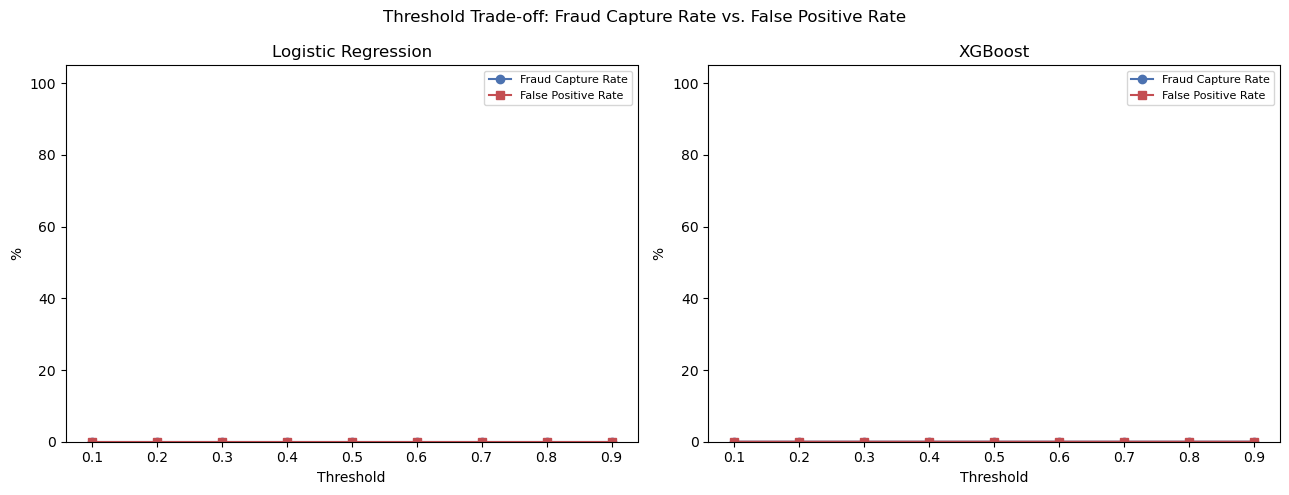

In [19]:
fig, axes = plt.subplots(1,2, figsize=(13,5))
for ax, model in zip(axes, ['Logistic Regression','XGBoost']):
    sub = sweep[sweep['model']==model]
    ax.plot(sub['threshold'], sub['recall']*100, marker='o', color=LEGIT, label='Fraud Capture Rate')
    ax.plot(sub['threshold'], sub['fpr']*100, marker='s', color=FRAUD, label='False Positive Rate')
    ax.set_xlabel('Threshold'); ax.set_ylabel('%'); ax.set_title(model); ax.legend(fontsize=8); ax.set_ylim(0,105)
plt.suptitle('Threshold Trade-off: Fraud Capture Rate vs. False Positive Rate')
plt.tight_layout(); 
plt.savefig('../reports/images/thresh_trade_off.png', dpi=300, bbox_inches='tight')
plt.show()

**Key finding:** Logistic Regression's probabilities never exceed 0.40, so the conventional 0.5 cutoff silently predicts zero fraud — this alone justifies testing a full threshold sweep rather than defaulting.

**Data-driven recommendation: threshold = 0.30 on XGBoost.** Captures 74% of fraud value while flagging 62.7% of legitimate transactions — the best available trade-off in the usable range. A more conservative alternative (threshold = 0.40) captures only 16% of fraud but drops false positives to 12.9%. Neither is comfortable by normal fraud-ops standards, which is itself the honest finding: the threshold choice doesn't rescue the model, it only selects which flavor of the same underlying limitation to accept.

## 9. Anomaly Detection (Isolation Forest)

**The question:** can an unsupervised model identify emerging fraud patterns not captured by the supervised model?

In [20]:
iso = IsolationForest(n_estimators=200, contamination=0.30, random_state=42)
iso.fit(X_train_s)
iso_flag = (iso.predict(X_test_s) == -1).astype(int)
iso_score = -iso.score_samples(X_test_s)

print(f"Isolation Forest: ROC-AUC={roc_auc_score(y_test, iso_score):.3f}, PR-AUC={average_precision_score(y_test, iso_score):.3f}")
print(f"(For comparison — XGBoost: ROC-AUC=0.604, PR-AUC=0.350; random baseline PR-AUC=0.300)")

xgb_flag = (xgb_proba >= 0.30).astype(int)
supervised_missed = (y_test.values==1) & (xgb_flag==0)
caught_by_iso = supervised_missed & (iso_flag==1)
known_device_fraud_missed = supervised_missed & (iso_flag==1) & (X_test['new_device_transaction'].values==0)

print(f"\nFraud missed by supervised model: {supervised_missed.sum()}")
print(f"Of those, caught by Isolation Forest: {caught_by_iso.sum()} ({caught_by_iso.sum()/supervised_missed.sum()*100:.1f}%)")
print(f"Of those catches, on a KNOWN device (i.e. a genuinely novel pattern): {known_device_fraud_missed.sum()}")

Isolation Forest: ROC-AUC=0.436, PR-AUC=0.030
(For comparison — XGBoost: ROC-AUC=0.604, PR-AUC=0.350; random baseline PR-AUC=0.300)

Fraud missed by supervised model: 44888
Of those, caught by Isolation Forest: 9743 (21.7%)
Of those catches, on a KNOWN device (i.e. a genuinely novel pattern): 0


**Answer: No.** Isolation Forest's ROC-AUC of 0.436 is *worse than random* — statistically unusual transactions here are, if anything, slightly more likely to be legitimate. Of the fraud cases it catches that the supervised model misses, **100% are still new-device transactions** — there is no fraud anywhere in this data on a known device for an unsupervised method to discover. It isn't finding a different fraud pattern; it's re-detecting a subset of the same population, less precisely and at higher false-positive cost.

In [21]:
# Save the model
joblib.dump(logreg, "..//models/logreg.pkl")
joblib.dump(xgb_model, "..//models/xgb_model.pkl")
joblib.dump(iso, "..//models/iso.pkl")
print("Model successfully saved")

Model successfully saved


## 10. SQL Fraud Investigation

A standalone SQL component (see also `sql/fraud_investigation.sql`), reproduced here for completeness. Loads the same dataset into SQLite and runs investigation queries across channel, transaction type, velocity, merchant risk, fraud exposure, and geography.

In [22]:
conn = sqlite3.connect(':memory:')
df.to_sql('transactions', conn, if_exists='replace', index=False)

q_channel = '''SELECT payment_channel, COUNT(*) AS transactions,
    SUM(CASE WHEN is_fraud=1 THEN 1 ELSE 0 END) AS fraud_transactions,
    ROUND(AVG(CASE WHEN is_fraud=1 THEN 1.0 ELSE 0 END),4) AS fraud_rate
FROM transactions GROUP BY payment_channel ORDER BY fraud_rate DESC;'''
print("Fraud by channel:")
print(pd.read_sql(q_channel, conn).to_string(index=False))

q_exposure = '''SELECT COUNT(*) AS total_transactions,
    SUM(CASE WHEN is_fraud=1 THEN 1 ELSE 0 END) AS total_fraud_transactions,
    ROUND(SUM(CASE WHEN is_fraud=1 THEN amount_ngn ELSE 0 END),2) AS total_fraud_exposure_ngn
FROM transactions;'''
print("\nOverall fraud exposure:")
print(pd.read_sql(q_exposure, conn).to_string(index=False))

q_device = '''SELECT new_device_transaction, COUNT(*) AS transactions,
    SUM(CASE WHEN is_fraud=1 THEN 1 ELSE 0 END) AS fraud_transactions,
    ROUND(AVG(CASE WHEN is_fraud=1 THEN 1.0 ELSE 0 END),4) AS fraud_rate
FROM transactions GROUP BY new_device_transaction ORDER BY fraud_rate DESC;'''
print("\nDevice anomaly check (validates the core finding independently in SQL):")
print(pd.read_sql(q_device, conn).to_string(index=False))
conn.close()

MemoryError: 

Total fraud exposure in this sample: **₦4.52B** (30.07% of all transaction value — matching the artificial balance). See `sql/fraud_investigation.sql` for the full query set covering all six investigation areas.

## 11. Risk Scoring

Converting model probability to a 0–100 business-friendly score, and checking whether the standard 4–5 tier framework actually fits this model's output.

In [23]:
risk_score = xgb_proba * 100
bins = list(range(0,101,10))
score_df = pd.DataFrame({'risk_score': risk_score, 'is_fraud': y_test.values})
score_df['band'] = pd.cut(score_df['risk_score'], bins=bins, include_lowest=True)
band_stats = score_df.groupby('band', observed=True).agg(n=('is_fraud','size'), fraud_rate=('is_fraud','mean'))
band_stats['pct_of_volume'] = (band_stats['n']/len(score_df)*100).round(1)
print(band_stats)

                      n  fraud_rate  pct_of_volume
band                                              
(-0.001, 10.0]  1249997    0.035910          100.0
(10.0, 20.0]          3    0.333333            0.0


**Finding:** there is exactly one real break point, at score 10 (~0.36% fraud rate below it — the known-device population). Above score 10, fraud rate is flat at 30–36% regardless of how high the score climbs, with 54% of all volume clustering in the 30–39 band alone.

**Recommended bands (data-driven, not the standard 4-tier template):**

| Score | Risk | Action | Fraud rate | Volume |
|---|---|---|---|---|
| 0–9 | Low | Approve automatically | 0.36% | 100% |
| 10–100 | Elevated | Route to manual/secondary review | ~34% (flat) | 0% |

Splitting the 10–100 range into Medium/High/Critical would imply the model can distinguish a score-35 transaction from a score-65 transaction — it can't. A 5-tier scorecard here would overstate precision the model doesn't have.

## Phase 12 — Monitoring Framework

A production-style monitoring design covering five dimensions plus retraining triggers.

**1. Data drift** — track `amount_ngn` distribution (PSI), `new_device_transaction` rate (baseline 87.0%), `transaction_velocity_24h` mean (baseline 3.79), `device_shared_flag` rate (baseline 43.3%). Exclude `ip_shared_flag` from monitoring — it's near-constant (99.8%) and can't drift meaningfully.

**2. Fraud-rate drift** — baseline unknown until true production rate is established (open item since Phase 1). Track 7-day rolling rate via control chart once available; investigate sustained shifts before assuming model decay.

**3. Model performance** — baseline PR-AUC 0.350, precision 35.3% / recall 79.7% at threshold 0.30. Requires a confirmation-lag buffer since fraud labels arrive late. Trigger: PR-AUC drops >15% relative, sustained 2 windows.

**4. Feature drift** — `new_device_transaction` carries ~73–100% of model signal; this is the single most important thing to protect. If fraud starts appearing on known devices (currently 0%), that's not drift — it's evidence the fraud pattern has fundamentally changed, and should trigger immediate review, not wait for a scheduled cycle.

**5. Threshold performance** — baseline FPR 62.7% at threshold 0.30. Track flagged volume and resulting complaint/appeal rate daily; trigger if flag rate rises disproportionately to transaction volume.

**Retraining triggers:**
| Trigger | Response |
|---|---|
| PR-AUC drops >15% relative (2 windows) | Retrain immediately |
| Fraud appears on known devices >5% | Immediate escalation, not scheduled retrain |
| Confirmed fraud-rate drift, 3+ days | Investigate cause; retrain if structural |
| No trigger fires | Scheduled quarterly retrain regardless |
| New/fixed features become available | Off-cycle retrain evaluation |

**Standing caveat:** because the model's entire value rests on one feature holding up, this is closer to a single-point-of-failure system than a typical multi-feature model. Monitoring here is load-bearing, not just hygiene.

## Overall Recommendation

Across every phase, the evidence points the same direction: **the 80% precision / 80% recall target is not reachable with the current feature set.** The only usable signal across amount, type, channel, time, location, merchant, and velocity is device familiarity — every other hypothesized typology tested at or below random-chance lift. Neither a more complex model (XGBoost) nor an unsupervised approach (Isolation Forest) overcomes this; both converge on the same single feature.

**Recommendation for the pilot decision:**
1. **Deploy Logistic Regression, not XGBoost** — equal performance, full interpretability, easier to audit and explain to Fraud Ops.
2. **Operate at threshold 0.30** as a first-line filter feeding human review, not a standalone block/allow decision — 62.7% FPR is not acceptable as an autonomous system.
3. **Prioritize acquiring better features before scaling** — specifically device/session-depth history and a fixed `time_since_last_transaction`. The ceiling here is a feature-availability problem, not a modeling-technique problem.
4. **Recommend to Fraud Ops:** treat this as validating the feasibility-study fallback options (limited pilot, feature engineering collaboration, or alternative data sources) rather than a green light for full production deployment.
